<a href="https://colab.research.google.com/github/gee666thu/Password-checker-/blob/main/exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

                              Model        MSE  R2 Score
0                 Linear Regression  22.299626  0.570192
1  Polynomial Regression (Degree 2)  21.661071  0.582499
2  Polynomial Regression (Degree 3)  22.145124  0.573170


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


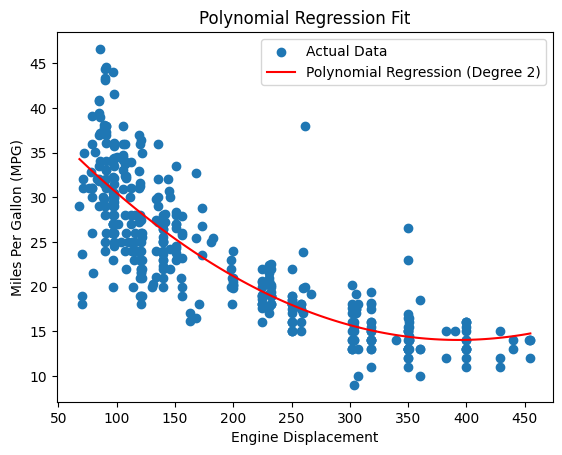

In [4]:
# ======================================================
# 1. IMPORT LIBRARIES
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# ======================================================
# 2. LOAD AND CLEAN DATA
# ======================================================
data = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv")
data.replace("?", np.nan, inplace=True)
data.dropna(inplace=True)
data["displacement"] = pd.to_numeric(data["displacement"], errors="coerce")
data["mpg"] = pd.to_numeric(data["mpg"], errors="coerce")
data.dropna(inplace=True)

# ======================================================
# 3. SELECT X AND Y
# ======================================================
X = data[["displacement"]]
y = data["mpg"]

# ======================================================
# 4. TRAIN TEST SPLIT
# ======================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ======================================================
# 5. LINEAR REGRESSION MODEL
# ======================================================
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

# ======================================================
# 6. POLYNOMIAL REGRESSION - DEGREE 2
# ======================================================
poly2 = PolynomialFeatures(degree=2)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)
poly_model2 = LinearRegression()
poly_model2.fit(X_train_poly2, y_train)
y_pred_poly2 = poly_model2.predict(X_test_poly2)
poly2_mse = mean_squared_error(y_test, y_pred_poly2)
poly2_r2 = r2_score(y_test, y_pred_poly2)

# ======================================================
# 7. POLYNOMIAL REGRESSION - DEGREE 3
# ======================================================
poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
poly_model3 = LinearRegression()
poly_model3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model3.predict(X_test_poly3)
poly3_mse = mean_squared_error(y_test, y_pred_poly3)
poly3_r2 = r2_score(y_test, y_pred_poly3)

# ======================================================
# 8. MODEL COMPARISON TABLE
# ======================================================
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (Degree 2)", "Polynomial Regression (Degree 3)"],
    "MSE": [linear_mse, poly2_mse, poly3_mse],
    "R2 Score": [linear_r2, poly2_r2, poly3_r2]
})
print(comparison)

# ======================================================
# 9. GRAPH - POLYNOMIAL REGRESSION FIT (DEGREE 2)
# ======================================================
X_plot = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_plot_poly2 = poly2.transform(X_plot)
y_plot_poly2 = poly_model2.predict(X_plot_poly2)
plt.scatter(X, y, label="Actual Data")
plt.plot(X_plot, y_plot_poly2, color="red", label="Polynomial Regression (Degree 2)")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Polynomial Regression Fit")
plt.legend()
plt.show()